Supplementary figure on feature condensation. Based on simulations

In [1]:
# ============================================================
# Supplementary Figure — IsoVita feature condensation
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from patsy import dmatrix, build_design_matrices

import isovita as iso
import isovita_simulation as isim

# ============================================================
# 1. Simulate feature-condensation cases
# ============================================================

SCENARIOS = isim.make_feature_condensation_scenarios()

sim_data = isim.simulate_isovita_dataset(
    SCENARIOS,
    n_samples=180,
    age_min=0,
    age_max=85,
    age_design="uniform",
    seed=20260927,
)

# Keep all simulation outputs in memory.
sim_tables = sim_data.as_dict()

display(sim_tables["scenario_table"])

print("Expression:", sim_tables["expression"].shape)
print("Fraction table:", sim_tables["fractions"].shape)
print("Component loading table:", sim_tables["component_loadings"].shape)

,scenario_index,gene_id,label,k,n_components,noise_sd,noise_corr,notes
0,0,COND_A,Two-isoform nonlinear contrast,2,2,0.2,0.1,"Reference case: with two isoforms, the composi..."
1,1,COND_B,Coherent multi-isoform groups,4,2,0.2,0.1,Four isoforms share a dominant two-group contr...
2,2,COND_C,Dominant contrast with passenger isoforms,5,2,0.2,0.1,The main temporal axis is TX1/TX2 versus TX3. ...
3,3,COND_D,Competing temporal modes,6,2,0.2,0.1,Stress test: a dominant four-isoform smooth co...


Expression: (17, 182)
Fraction table: (3060, 13)
Component loading table: (34, 7)


In [2]:
# ============================================================
# 2. Run IsoVita feature condensation only
# ============================================================

sample_cols = sim_data.metadata.index.tolist()

(
    balance_summary,
    balance_loadings,
    balance_feature_matrix,
) = iso.build_one_feature_per_gene(
    expression_df=sim_data.expression,
    global_metrics=sim_data.global_metrics,
    sample_cols=sample_cols,
    metadata=sim_data.metadata,
    config=iso.BalanceConfig(),
)

# Keep all learned quantities in memory as well.
condensation_tables = {
    **sim_tables,
    "balance_summary": balance_summary,
    "balance_loadings": balance_loadings,
    "balance_feature_matrix": balance_feature_matrix,
}

summary_cols = [
    "gene_id",
    "group_A",
    "group_B",
    "unused_isoforms",
    "n_used",
    "cosine_similarity",
    "pc1_explained_variance_ratio",
    "feature_robust_amplitude",
]

display(
    balance_summary[summary_cols]
    .sort_values("gene_id")
    .reset_index(drop=True)
)

,gene_id,group_A,group_B,unused_isoforms,n_used,cosine_similarity,pc1_explained_variance_ratio,feature_robust_amplitude
0,COND_A,COND_A_TX2,COND_A_TX1,,2,1.000000,1.000000,4.008175
1,COND_B,COND_B_TX3|COND_B_TX4,COND_B_TX1|COND_B_TX2,,4,0.996383,0.999830,3.810180
2,COND_C,COND_C_TX3,COND_C_TX1|COND_C_TX2,COND_C_TX4|COND_C_TX5,3,0.969242,0.997197,3.958894
3,COND_D,COND_D_TX3|COND_D_TX4,COND_D_TX1|COND_D_TX2,COND_D_TX5|COND_D_TX6,4,0.994037,0.770204,3.593945


In [3]:
# ============================================================
# 3. Plotting helpers
# ============================================================

GROUP_COLORS = {
    1: "#D55E00",   # Group A
    -1: "#0072B2",  # Group B
    0: "#999999",   # unused
}

GROUP_NAMES = {
    1: "A",
    -1: "B",
    0: "unused",
}

LINESTYLES = [
    "-",
    "--",
    "-.",
    ":",
    (0, (5, 2)),
    (0, (1, 1)),
]


def short_tx(tx, gene):
    """COND_C_TX3 -> TX3."""
    return str(tx).replace(f"{gene}_", "")


def split_group(value, gene):
    """Compact a pipe-delimited IsoVita group for plotting."""
    if not isinstance(value, str) or value == "":
        return "—"

    return ", ".join(
        short_tx(tx, gene)
        for tx in value.split("|")
    )


def spline_smooth(
    age,
    y,
    *,
    df=4,
    degree=3,
    grid_size=200,
):
    """
    Descriptive spline used only to visualize the learned
    sample-level condensed feature.
    """
    age = np.asarray(age, dtype=float)
    y = np.asarray(y, dtype=float)

    order = np.argsort(age)
    age_sorted = age[order]
    y_sorted = y[order]

    formula = (
        f"bs(age, df={df}, degree={degree}, "
        "include_intercept=False)"
    )

    X_df = dmatrix(
        formula,
        {"age": age_sorted},
        return_type="dataframe",
    )

    X = np.asarray(
        X_df,
        dtype=float,
    )

    beta = np.linalg.lstsq(
        X,
        y_sorted,
        rcond=None,
    )[0]

    age_grid = np.linspace(
        age_sorted.min(),
        age_sorted.max(),
        grid_size,
    )

    X_grid = np.asarray(
        build_design_matrices(
            [X_df.design_info],
            {"age": age_grid},
        )[0],
        dtype=float,
    )

    fitted = X_grid @ beta

    return age_grid, fitted

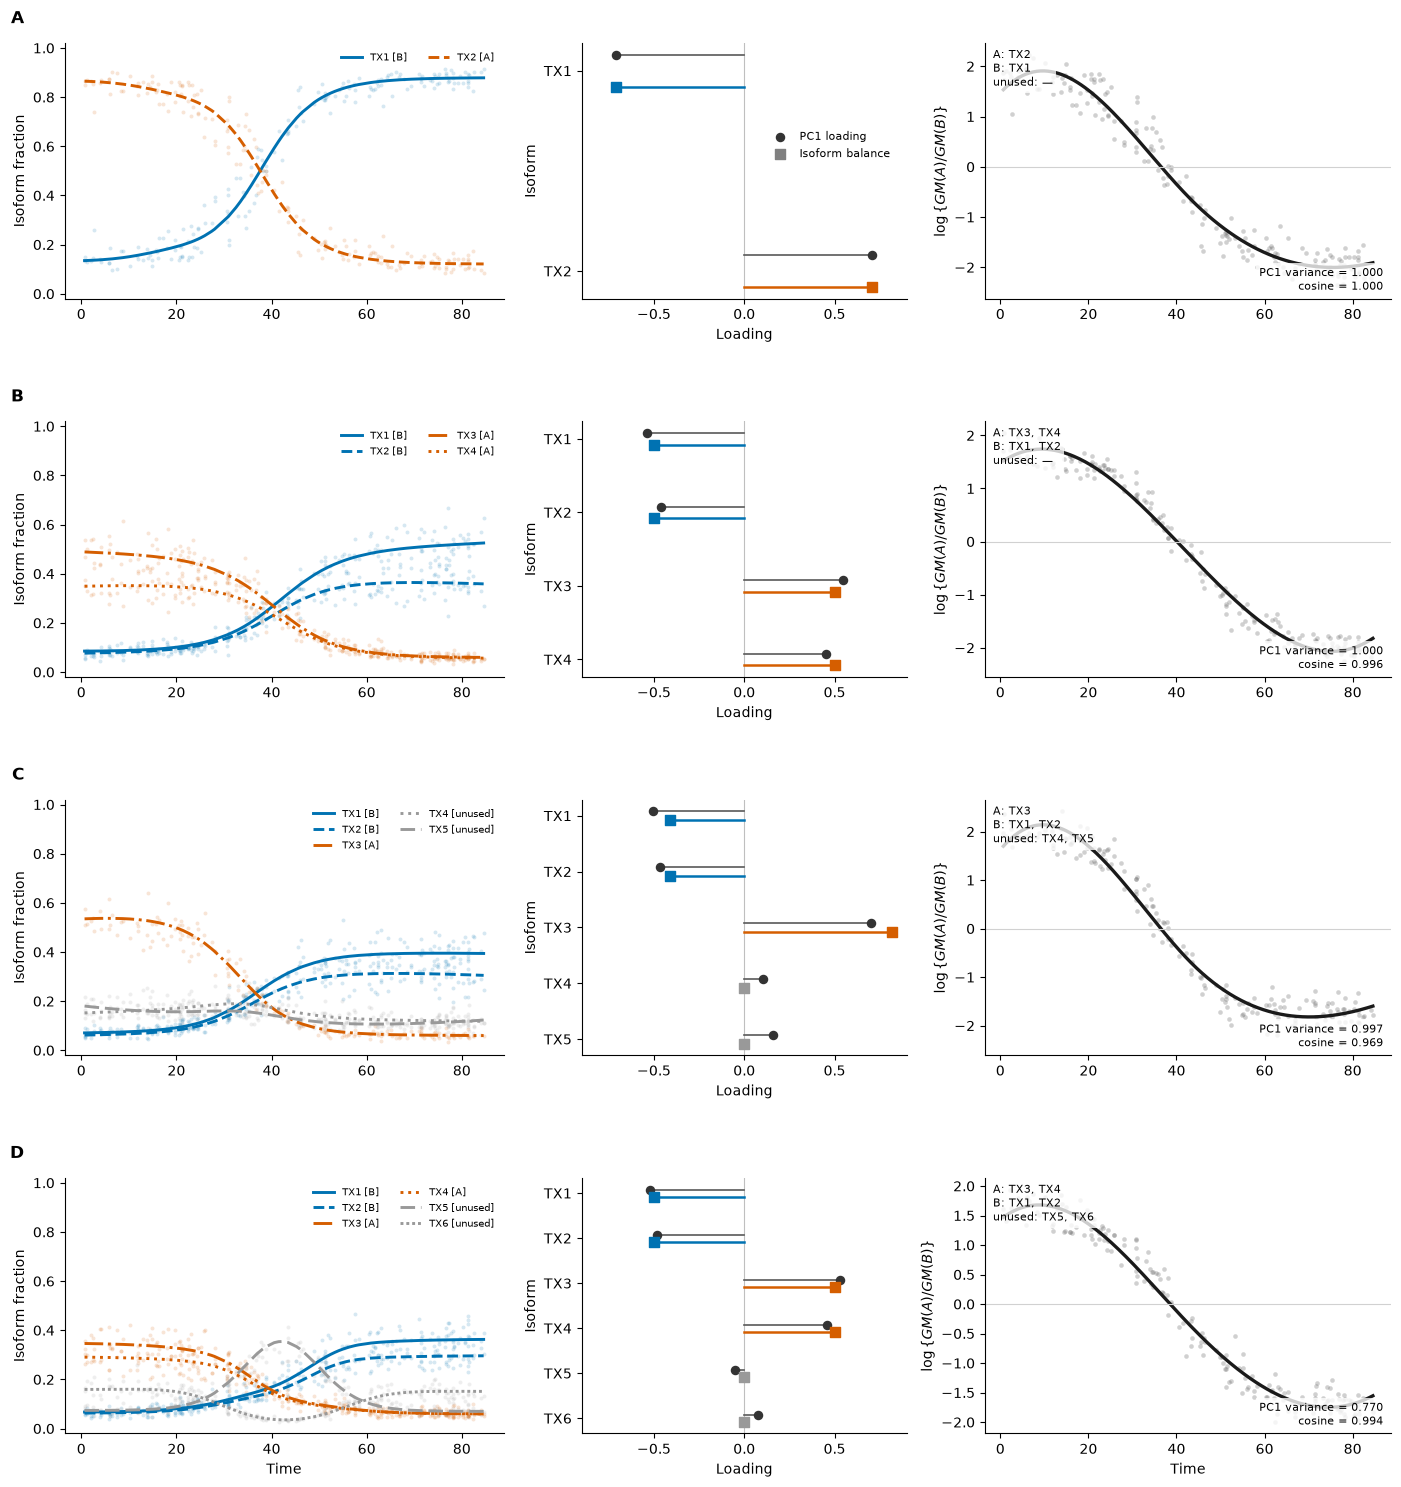

In [4]:
# ============================================================
# 4. Build final supplementary figure
# ============================================================

fig, axes = plt.subplots(
    len(SCENARIOS),
    3,
    figsize=(14.5, 15.8),
    gridspec_kw={
        "width_ratios": [1.35, 1.0, 1.25],
    },
)

fig.subplots_adjust(
    left=0.07,
    right=0.985,
    bottom=0.055,
    top=0.935,
    wspace=0.20,
    hspace=0.48,
)

summary_by_gene = (
    balance_summary
    .set_index("gene_id")
)


for row, scenario in enumerate(SCENARIOS):

    gene = scenario.gene_id

    ax_frac = axes[row, 0]
    ax_load = axes[row, 1]
    ax_feature = axes[row, 2]

    # --------------------------------------------------------
    # Learned PC1 / balance information for this gene
    # --------------------------------------------------------

    load = (
        balance_loadings
        .query("gene_id == @gene")
        .copy()
        .sort_values("transcript_id")
        .reset_index(drop=True)
    )

    assignment_map = (
        load
        .set_index("transcript_id")[
            "balance_assignment"
        ]
        .astype(int)
        .to_dict()
    )

    tx_order = load["transcript_id"].tolist()

    # ========================================================
    # LEFT: simulated isoform composition
    # ========================================================

    frac = (
        sim_data.fractions
        .query("gene_id == @gene")
        .copy()
    )

    for j, tx in enumerate(tx_order):

        sub = (
            frac.loc[
                frac["transcript_id"].eq(tx)
            ]
            .sort_values("age")
        )

        assignment = int(
            assignment_map[tx]
        )

        color = GROUP_COLORS[
            assignment
        ]

        linestyle = LINESTYLES[
            j % len(LINESTYLES)
        ]

        label = (
            f"{short_tx(tx, gene)} "
            f"[{GROUP_NAMES[assignment]}]"
        )

        # Noisy observed fractions.
        ax_frac.scatter(
            sub["age"],
            sub["fraction"],
            s=8,
            alpha=0.16,
            color=color,
            linewidths=0,
        )

        # Noise-free underlying trajectory.
        ax_frac.plot(
            sub["age"],
            sub["true_fraction"],
            lw=2.1,
            ls=linestyle,
            color=color,
            label=label,
        )

    ax_frac.set_ylim(
        -0.02,
        1.02,
    )

    ax_frac.set_ylabel(
        "Isoform fraction"
    )

    if row == len(SCENARIOS) - 1:
        ax_frac.set_xlabel(
            "Time"
        )

    ax_frac.legend(
        frameon=False,
        fontsize=7.5,
        ncol=2,
        loc="best",
    )

    # ========================================================
    # MIDDLE: continuous PC1 versus isoform balance
    # ========================================================

    y_pos = np.arange(
        len(load)
    )

    pc1 = load[
        "pc1_loading"
    ].to_numpy(float)

    sparse = load[
        "balance_direction"
    ].to_numpy(float)

    assignments = load[
        "balance_assignment"
    ].to_numpy(int)

    ax_load.axvline(
        0,
        lw=0.8,
        color="0.75",
        zorder=0,
    )

    for i, (
        pc1_value,
        sparse_value,
        assignment,
    ) in enumerate(
        zip(
            pc1,
            sparse,
            assignments,
        )
    ):

        # Dense PC1.
        ax_load.plot(
            [0, pc1_value],
            [i - 0.08, i - 0.08],
            color="0.35",
            lw=1.2,
        )

        ax_load.scatter(
            pc1_value,
            i - 0.08,
            s=34,
            color="0.20",
            zorder=3,
        )

        # Learned sparse balance.
        ax_load.plot(
            [0, sparse_value],
            [i + 0.08, i + 0.08],
            color=GROUP_COLORS[
                int(assignment)
            ],
            lw=1.8,
        )

        ax_load.scatter(
            sparse_value,
            i + 0.08,
            s=42,
            marker="s",
            color=GROUP_COLORS[
                int(assignment)
            ],
            zorder=3,
        )

    ax_load.set_yticks(
        y_pos
    )

    ax_load.set_yticklabels(
        [
            short_tx(tx, gene)
            for tx in load[
                "transcript_id"
            ]
        ]
    )

    ax_load.invert_yaxis()

    ax_load.set_xlim(
        -0.9,
        0.9,
    )

    ax_load.set_xlabel(
        "Loading"
    )

    ax_load.set_ylabel(
        "Isoform"
    )

    if row == 0:

        ax_load.scatter(
            [],
            [],
            s=34,
            color="0.20",
            label="PC1 loading",
        )

        ax_load.scatter(
            [],
            [],
            s=42,
            marker="s",
            color="0.50",
            label="Isoform balance",
        )

        ax_load.legend(
            frameon=False,
            fontsize=8,
            loc="center right",
            bbox_to_anchor=(0.98, 0.60),
        )

    # ========================================================
    # RIGHT: final condensed gene feature
    # ========================================================

    samples = (
        sim_data.metadata
        .index
        .tolist()
    )

    age = (
        sim_data.metadata
        .loc[
            samples,
            "age",
        ]
        .to_numpy(float)
    )

    feature = (
        balance_feature_matrix
        .loc[
            gene,
            samples,
        ]
        .to_numpy(float)
    )

    age_grid, feature_smooth = (
        spline_smooth(
            age,
            feature,
        )
    )

    ax_feature.scatter(
        age,
        feature,
        s=11,
        alpha=0.28,
        color="0.35",
        linewidths=0,
    )

    ax_feature.plot(
        age_grid,
        feature_smooth,
        lw=2.4,
        color="0.10",
    )

    ax_feature.axhline(
        0,
        lw=0.8,
        color="0.82",
    )

    ax_feature.set_ylabel(
        r"$\log\{GM(A)/GM(B)\}$"
    )

    if row == len(SCENARIOS) - 1:
        ax_feature.set_xlabel(
            "Time"
        )

    # --------------------------------------------------------
    # Compact learned grouping + diagnostics
    # --------------------------------------------------------

    summary = (
        summary_by_gene
        .loc[gene]
    )

    group_text = (
        f"A: "
        f"{split_group(summary['group_A'], gene)}\n"
        f"B: "
        f"{split_group(summary['group_B'], gene)}\n"
        f"unused: "
        f"{split_group(summary['unused_isoforms'], gene)}"
    )

    metric_text = (
        "PC1 variance = "
        f"{summary['pc1_explained_variance_ratio']:.3f}\n"
        "cosine = "
        f"{summary['cosine_similarity']:.3f}"
    )

    ax_feature.text(
        0.02,
        0.98,
        group_text,
        transform=ax_feature.transAxes,
        ha="left",
        va="top",
        fontsize=8.2,
        bbox={
            "facecolor": "white",
            "edgecolor": "none",
            "alpha": 0.78,
            "pad": 2.5,
        },
    )

    ax_feature.text(
        0.98,
        0.02,
        metric_text,
        transform=ax_feature.transAxes,
        ha="right",
        va="bottom",
        fontsize=8.2,
        bbox={
            "facecolor": "white",
            "edgecolor": "none",
            "alpha": 0.78,
            "pad": 2.5,
        },
    )


# ============================================================
# Cosmetics
# ============================================================

for ax in axes.ravel():

    ax.spines[
        "top"
    ].set_visible(False)

    ax.spines[
        "right"
    ].set_visible(False)


# Resolve axis positions before adding figure-level text.
fig.canvas.draw()


# ============================================================
# Panel letters
# ============================================================

for row in range(
    len(SCENARIOS)
):

    pos = (
        axes[row, 0]
        .get_position()
    )

    fig.text(
        pos.x0 - 0.028,
        pos.y1 + 0.010,
        chr(65 + row),
        ha="right",
        va="bottom",
        fontsize=12.5,
        fontweight="bold",
    )


plt.show()